# Phase 4: Exploratory Data Analysis (EDA)

## Bank Marketing Subscription Prediction

### Objective

Discover patterns, distributions and relationships in the Bank Marketing dataset.

This phase focuses on numerical and categorical exploratory analysis,
customer behavior, subscription patterns and business insights.

Every visualization will include:
- Observation: What the graph actually shows.
- Business Insight: What the finding means for the bank.

### Sessions

- Session 1: Numerical EDA
- Session 2: Categorical EDA

## 1. Import Libraries and Configure Visualization Settings

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Visualization settings
sns.set_theme(style="whitegrid", palette="deep")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100

# Project paths
DATA_PATH = Path("../data/processed/cleaned_data.csv")
FIGURE_PATH = Path("../images/eda")

FIGURE_PATH.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")
print("Data path:", DATA_PATH.resolve())
print("Figure directory:", FIGURE_PATH.resolve())

Libraries imported successfully.
Data path: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/data/processed/cleaned_data.csv
Figure directory: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/images/eda


## 2. Load the Cleaned Dataset

In [2]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

display(df.head())

print("\nDataset information:")
df.info()

Dataset shape: (4521, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 6   housing    4521 non-null   str  
 7   loan       4521 non-null   str  
 8   contact    4521 non-null   str  
 9   day        4521 non-null   int64
 10  month      4521 non-null   str  
 11  duration   4521 non-null   int64
 12  campaign   4521 non-null   int64
 13  pdays      4521 non-null   int64
 14  previous   4521 non-null   int64
 15  poutcome   4521 non-null   str  
 16  y          4521 non-null   str  
dtypes: int64(7), str(10)
memory usage: 826.8 KB


## 3. Initial Dataset Overview

In [3]:
print("Numerical Features:")
display(df.describe().T)

print("\nCategorical Features:")
display(df.describe(include="object").T)

print("\nTarget Distribution:")
display(df["y"].value_counts())

Numerical Features:


,count,mean,std,min,25%,50%,75%,max
age,4521.0,41.170095,10.576211,19.0,33.0,39.0,49.0,87.0
balance,4521.0,1422.657819,3009.638142,-3313.0,69.0,444.0,1480.0,71188.0
day,4521.0,15.915284,8.247667,1.0,9.0,16.0,21.0,31.0
duration,4521.0,263.961292,259.856633,4.0,104.0,185.0,329.0,3025.0
campaign,4521.0,2.793630,3.109807,1.0,1.0,2.0,3.0,50.0
pdays,4521.0,39.766645,100.121124,-1.0,-1.0,-1.0,-1.0,871.0
previous,4521.0,0.542579,1.693562,0.0,0.0,0.0,0.0,25.0



Categorical Features:


/var/folders/0t/4hxrj7sn0vvg08hw1dqpc2g80000gn/T/ipykernel_3995/2583978559.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object").T)


,count,unique,top,freq
job,4521,12,management,969
marital,4521,3,married,2797
education,4521,4,secondary,2306
default,4521,2,no,4445
housing,4521,2,yes,2559
loan,4521,2,no,3830
contact,4521,3,cellular,2896
month,4521,12,may,1398
poutcome,4521,4,unknown,3705
y,4521,2,no,4000



Target Distribution:


y
no     4000
yes     521
Name: count, dtype: int64

## 4. Target Distribution Analysis

The target variable `y` represents whether a customer subscribed
to the bank's term deposit.

- no: Customer did not subscribe.
- yes: Customer subscribed.

We analyze the target distribution to understand class imbalance
and the overall subscription proportion.

,Count,Percentage
y,,
no,4000,88.48
yes,521,11.52


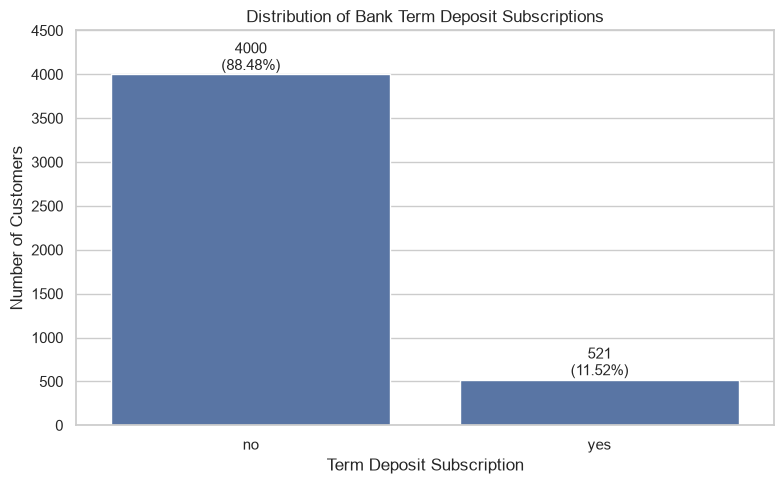

In [5]:
# Calculate target counts and percentages

target_counts = df["y"].value_counts().reindex(["no", "yes"])

target_percentages = (
    df["y"].value_counts(normalize=True).reindex(["no", "yes"]) * 100
)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages
})

display(target_summary.round(2))

# Create target distribution visualization

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="y",
    order=["no", "yes"]
)

plt.title("Distribution of Bank Term Deposit Subscriptions")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")

# Add count and percentage labels
for i, bar in enumerate(ax.patches):
    count = int(bar.get_height())
    percentage = target_percentages.iloc[i]

    ax.annotate(
        f"{count}\n({percentage:.2f}%)",
        (bar.get_x() + bar.get_width() / 2, count),
        ha="center",
        va="bottom",
        fontsize=11
    )
plt.ylim(0, 4500)
plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "01_target_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Observation

The target distribution shows that 4,000 customers (88.48%)
did not subscribe to the term deposit, while 521 customers
(11.52%) subscribed.

The dataset is significantly imbalanced, with approximately
7.68 times more non-subscribers than subscribers.

### Business Insight

Only a small proportion of contacted customers subscribed
to the term deposit.

The bank should investigate customer characteristics and
campaign-related factors associated with successful subscriptions.

For predictive modeling, accuracy alone may be misleading
because a model could favor the majority class.

Precision, recall, F1-score and PR-AUC will be important
evaluation metrics.

In [6]:
target_figure = FIGURE_PATH / "01_target_distribution.png"

print("Figure exists:", target_figure.exists())

if target_figure.exists():
    print("Figure size:", round(target_figure.stat().st_size / 1024, 2), "KB")

Figure exists: True
Figure size: 92.18 KB


## 5. Age Distribution Analysis

Age is a numerical customer characteristic.

We analyze its distribution to understand:
- The age range of contacted customers.
- The most common customer age groups.
- The spread and shape of the age distribution.
- Whether the dataset contains unusually young or old customers.

,Age Statistics
count,4521.000000
mean,41.170095
std,10.576211
min,19.000000
25%,33.000000
50%,39.000000
75%,49.000000
max,87.000000


Median age: 39.0
Skewness: 0.7


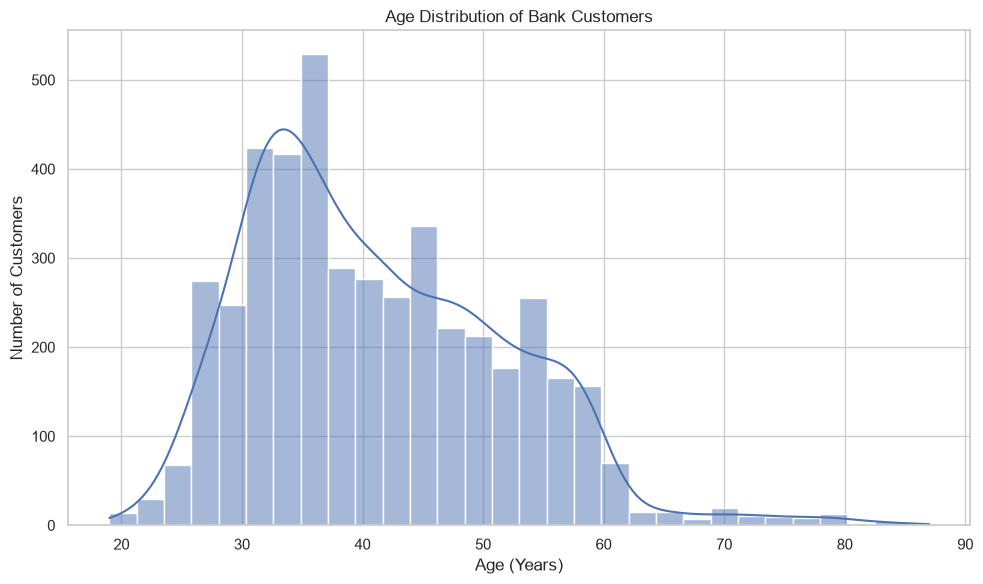

In [7]:
# Calculate age statistics

age_summary = df["age"].describe()

display(age_summary.to_frame(name="Age Statistics"))

print("Median age:", df["age"].median())
print("Skewness:", round(df["age"].skew(), 3))

# Create age distribution histogram

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="age",
    bins=30,
    kde=True
)

plt.title("Age Distribution of Bank Customers")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "02_age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Observation

The age distribution shows that customer ages range from 19 to 87 years.

The average age is 41.17 years, while the median age is 39 years.
Most customers are concentrated approximately between 30 and 50 years.

The distribution has a positive skewness of 0.70, indicating a
right-skewed distribution.

The mean being greater than the median also supports this observation.

### Business Insight

The bank's contacted customer base is primarily composed of adults
in their 30s and 40s.

The bank can investigate subscription behavior across different
age groups to identify customer segments with higher subscription rates.

Age-based segmentation may help improve customer targeting and
campaign personalization.

In [8]:
age_figure = FIGURE_PATH / "02_age_distribution.png"

print("Figure exists:", age_figure.exists())

if age_figure.exists():
    print(
        "Figure size:",
        round(age_figure.stat().st_size / 1024, 2),
        "KB"
    )

Figure exists: True
Figure size: 134.5 KB


## 6. Numerical Feature Boxplot Analysis

Boxplots are used to examine the distribution and spread of numerical
features and identify potential statistical outliers.

Features analyzed:
1. Age
2. Balance
3. Day
4. Duration
5. Campaign
6. Pdays
7. Previous

Duration is included for exploratory analysis but remains excluded
from predictive model inputs because of potential target leakage.

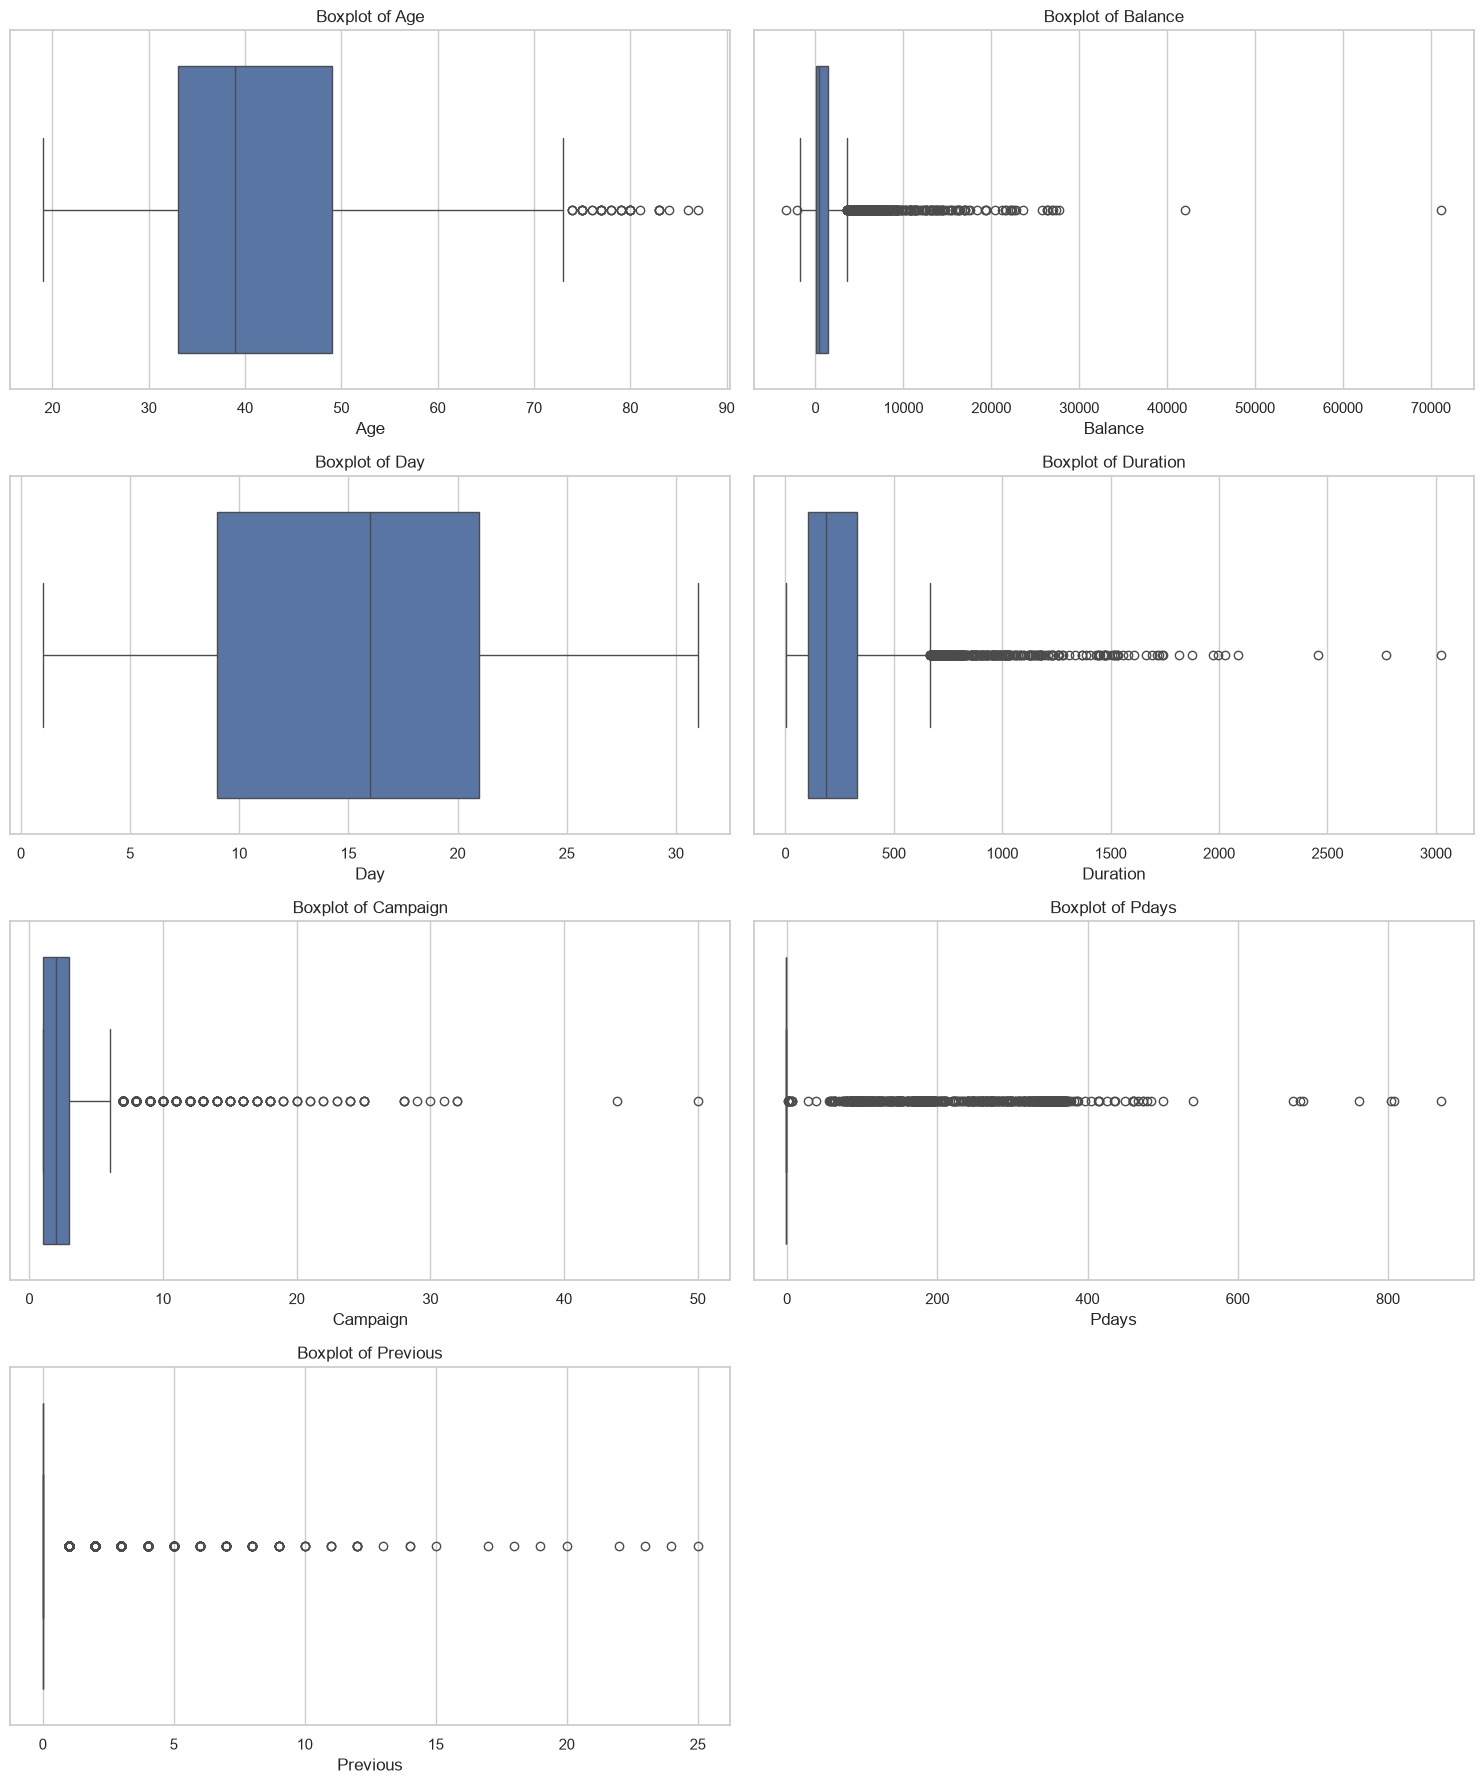

In [9]:
# Numerical features
numerical_features = [
    "age",
    "balance",
    "day",
    "duration",
    "campaign",
    "pdays",
    "previous"
]

# Create boxplots
fig, axes = plt.subplots(4, 2, figsize=(15, 18))

axes = axes.flatten()

for i, feature in enumerate(numerical_features):
    sns.boxplot(
        data=df,
        x=feature,
        ax=axes[i]
    )

    axes[i].set_title(f"Boxplot of {feature.capitalize()}")
    axes[i].set_xlabel(feature.capitalize())

# Remove unused subplot
fig.delaxes(axes[7])

plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "03_numerical_feature_boxplots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
outlier_summary = []

for feature in numerical_features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ]

    outlier_summary.append({
        "Feature": feature,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": len(outliers) / len(df) * 100
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df.round(2))

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,age,33.0,49.0,16.0,9.0,73.0,38,0.84
1,balance,69.0,1480.0,1411.0,-2047.5,3596.5,506,11.19
2,day,9.0,21.0,12.0,-9.0,39.0,0,0.00
3,duration,104.0,329.0,225.0,-233.5,666.5,330,7.30
4,campaign,1.0,3.0,2.0,-2.0,6.0,318,7.03
5,pdays,-1.0,-1.0,0.0,-1.0,-1.0,816,18.05
6,previous,0.0,0.0,0.0,0.0,0.0,816,18.05


### Observation

The numerical boxplots show different distributions across the features.

1. Age has 38 IQR outliers (0.84%), indicating relatively few extreme age values.
2. Balance has 506 IQR outliers (11.19%) and a strongly right-skewed distribution.
3. Day has no IQR outliers.
4. Duration has 330 IQR outliers (7.30%) and a long right tail.
5. Campaign has 318 IQR outliers (7.03%), showing that some customers received many contacts.
6. Pdays has 816 flagged observations (18.05%). However, its IQR is zero because Q1 and Q3 are both -1.
7. Previous also has 816 flagged observations (18.05%) because Q1 and Q3 are both zero.

The IQR method is therefore not meaningful for pdays and previous
when applied to their complete distributions.

### Business Insight

Customer balances vary considerably, and the bank can investigate
whether financial characteristics are associated with subscription behavior.

Some customers receive substantially more campaign contacts than others.
The bank can investigate whether repeated contact is effective.

Duration provides information about completed calls and can be useful
for post-campaign analysis, but it must remain excluded from pre-call
predictive model inputs.

The pdays and previous features contain important campaign-history
information. Their sentinel and zero-heavy distributions should be
handled carefully during analysis.

Statistical outliers are not automatically invalid observations.
Legitimate extreme values are retained rather than removed.

## 7. Correlation Analysis of Numerical Features

Correlation analysis helps identify the strength and direction
of linear relationships between numerical features.

Pearson correlation coefficients range from -1 to +1.

- +1: Perfect positive correlation.
- 0: No linear correlation.
- -1: Perfect negative correlation.

Duration is included for exploratory analysis but excluded
from pre-call predictive model inputs.

,age,balance,day,duration,campaign,pdays,previous
age,1.000,0.084,-0.018,-0.002,-0.005,-0.009,-0.004
balance,0.084,1.000,-0.009,-0.016,-0.010,0.009,0.026
day,-0.018,-0.009,1.000,-0.025,0.161,-0.094,-0.059
duration,-0.002,-0.016,-0.025,1.000,-0.068,0.010,0.018
campaign,-0.005,-0.010,0.161,-0.068,1.000,-0.093,-0.068
pdays,-0.009,0.009,-0.094,0.010,-0.093,1.000,0.578
previous,-0.004,0.026,-0.059,0.018,-0.068,0.578,1.000


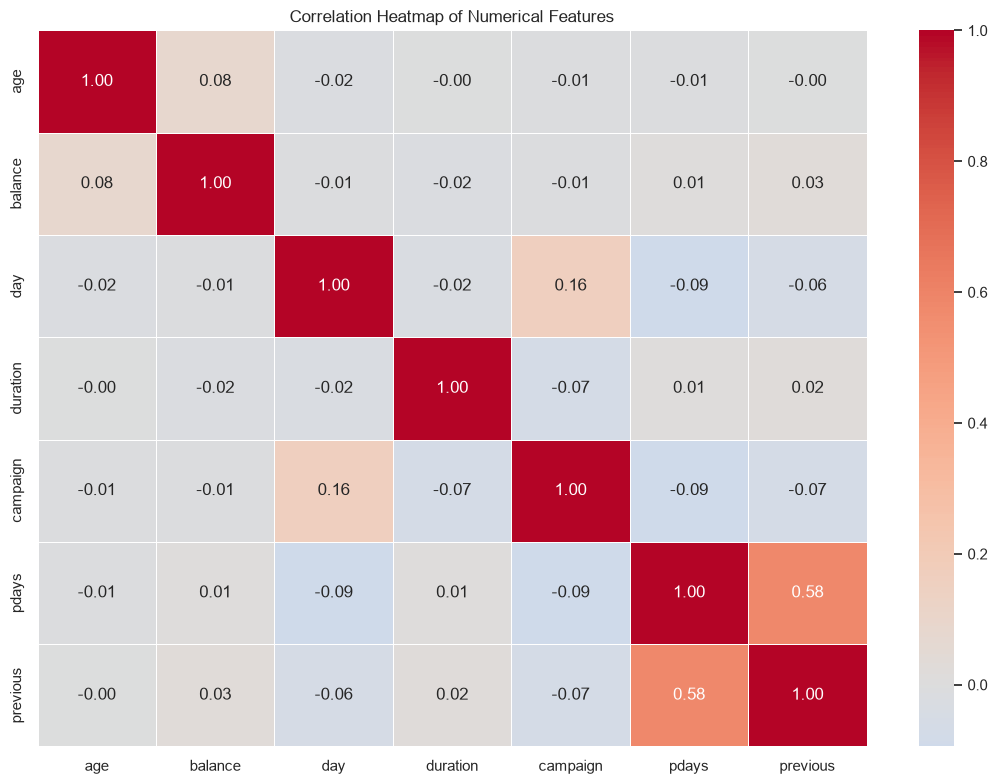

In [11]:
# Select numerical features
correlation_features = [
    "age",
    "balance",
    "day",
    "duration",
    "campaign",
    "pdays",
    "previous"
]

# Calculate Pearson correlation matrix
correlation_matrix = df[correlation_features].corr(method="pearson")

display(correlation_matrix.round(3))

# Create correlation heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")

plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "04_numerical_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Observation

The correlation heatmap reveals the following relationships:

1. Pdays and previous have the strongest positive correlation
   of approximately 0.578, indicating a moderate positive relationship.

2. Day and campaign have a weak positive correlation of 0.161.

3. Age and balance have a very weak positive correlation of 0.084.

4. Most other numerical feature pairs have weak correlations
   close to zero.

5. No pair of numerical predictors shows an extremely strong
   linear correlation.

### Business Insight

The moderate relationship between pdays and previous suggests
that customer contact history contains related information.

The generally weak correlations indicate that most numerical
features capture different aspects of customer information.

The bank can investigate these features together when developing
predictive models.

Correlation does not imply causation, and weak pairwise correlation
does not mean a feature is unimportant for predicting subscription.

Duration is included in this exploratory analysis but remains
excluded from pre-call model inputs because of potential target leakage.


In [12]:
correlation_figure = FIGURE_PATH / "04_numerical_correlation_heatmap.png"

print("Figure exists:", correlation_figure.exists())

if correlation_figure.exists():
    print(
        "Figure size:",
        round(correlation_figure.stat().st_size / 1024, 2),
        "KB"
    )

Figure exists: True
Figure size: 207.52 KB


## 8. Job Distribution and Subscription Rate Analysis

This analysis examines the distribution of customers across different
job categories and compares their term-deposit subscription rates.

The analysis includes:

1. Customer count by job category.
2. Subscription count by job category.
3. Subscription rate by job category.

Subscription rate is calculated as:

(Number of customers who subscribed / Total customers in that job category) × 100

In [13]:
# Calculate customer count and subscription statistics by job

job_summary = (
    df.groupby("job")
    .agg(
        Total_Customers=("y", "count"),
        Subscribers=("y", lambda x: (x == "yes").sum())
    )
)

job_summary["Non_Subscribers"] = (
    job_summary["Total_Customers"] - job_summary["Subscribers"]
)

job_summary["Subscription_Rate"] = (
    job_summary["Subscribers"] /
    job_summary["Total_Customers"] * 100
)

job_summary = job_summary.sort_values(
    "Subscription_Rate",
    ascending=False
)

display(job_summary.round(2))

,Total_Customers,Subscribers,Non_Subscribers,Subscription_Rate
job,,,,
retired,230,54,176,23.48
student,84,19,65,22.62
unknown,38,7,31,18.42
management,969,131,838,13.52
housemaid,112,14,98,12.50
admin.,478,58,420,12.13
self-employed,183,20,163,10.93
technician,768,83,685,10.81
unemployed,128,13,115,10.16


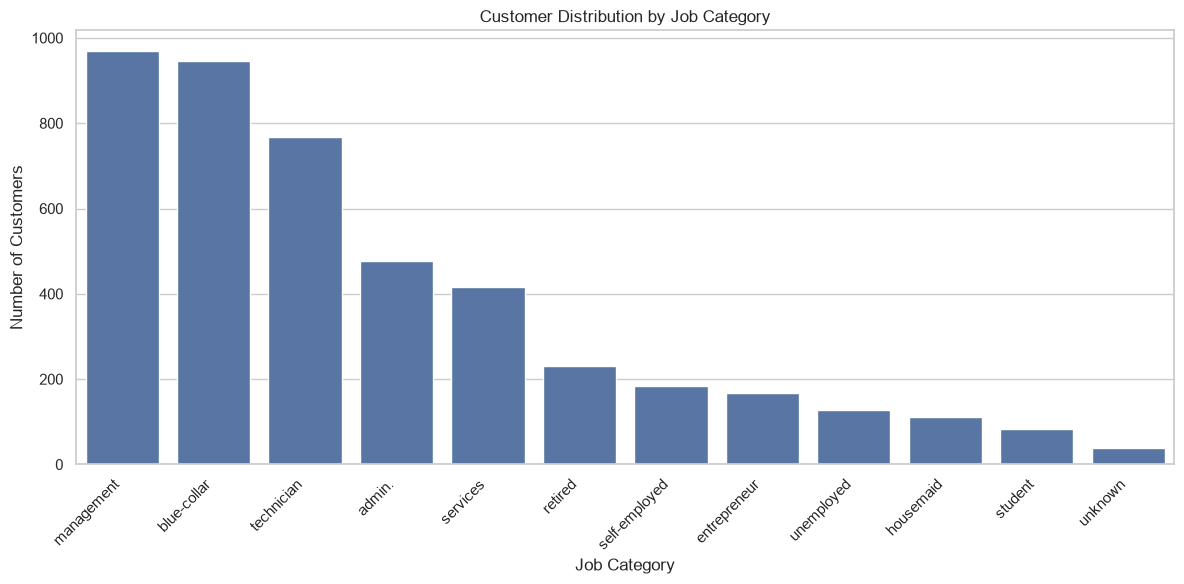

In [14]:
plt.figure(figsize=(12, 6))

job_counts = df["job"].value_counts().sort_values(ascending=False)

sns.barplot(
    x=job_counts.index,
    y=job_counts.values
)

plt.title("Customer Distribution by Job Category")
plt.xlabel("Job Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "05_job_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

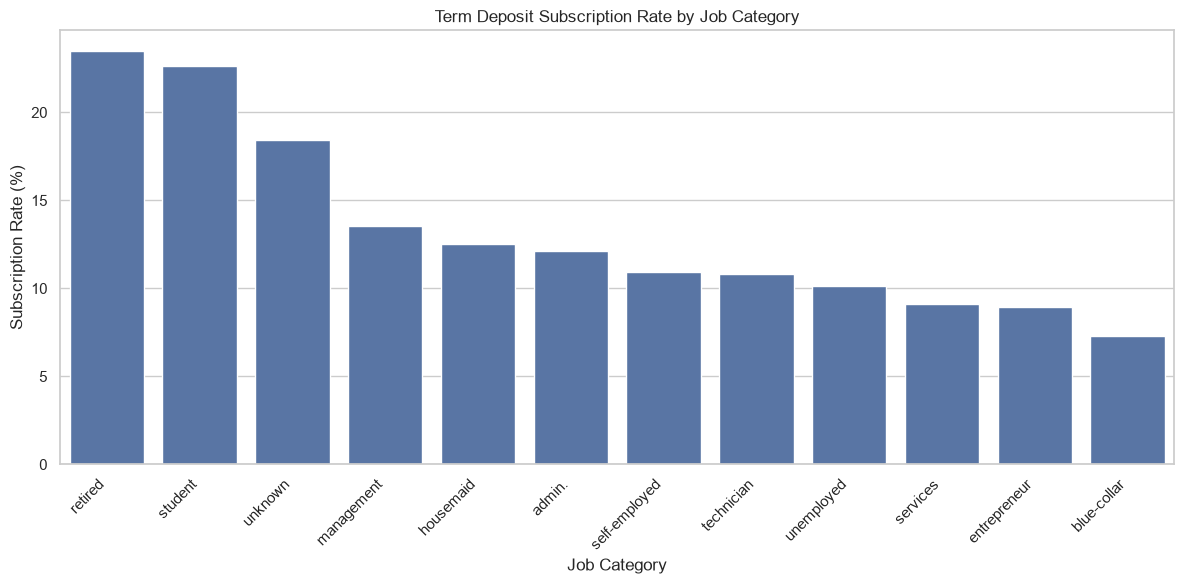

In [15]:
job_rates = job_summary.sort_values(
    "Subscription_Rate",
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=job_rates.reset_index(),
    x="job",
    y="Subscription_Rate"
)

plt.title("Term Deposit Subscription Rate by Job Category")
plt.xlabel("Job Category")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "06_subscription_rate_by_job.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
job_figures = [
    FIGURE_PATH / "05_job_distribution.png",
    FIGURE_PATH / "06_subscription_rate_by_job.png"
]

for figure in job_figures:
    print(
        figure.name,
        "| Exists:", figure.exists(),
        "| Size:", round(figure.stat().st_size / 1024, 2)
        if figure.exists() else "N/A",
        "KB"
    )

05_job_distribution.png | Exists: True | Size: 139.45 KB
06_subscription_rate_by_job.png | Exists: True | Size: 140.19 KB


### Observation

The job distribution shows that management has the largest number
of customers (969), followed by blue-collar (946) and technician (768).

Retired customers have the highest observed subscription rate
of 23.48%, followed by students at 22.62%.

Unknown job categories have a subscription rate of 18.42%,
but this category contains only 38 customers.

Blue-collar customers have the lowest subscription rate at 7.29%.

The results show that the most common job category does not
necessarily have the highest subscription rate.

### Business Insight

The bank can investigate retired and student customers as potentially
promising segments for term-deposit campaigns.

Management customers represent a large contacted segment and have
a subscription rate of 13.52%, making them another segment worth analyzing.

The bank can investigate whether different campaign strategies
are needed for blue-collar customers.

Subscription rates for categories with small customer counts
should be interpreted cautiously.

These results show associations and do not establish causation.

## 6. Categorical Feature Analysis

This section investigates how customer subscription rates vary
across education, marital status, housing loan, personal loan,
month, previous campaign outcome and campaign contacts.

For each feature, we will examine:
- Total customers in each category.
- Number of successful subscriptions.
- Number of unsuccessful subscriptions.
- Subscription rate (%).

The analysis will use actual observed counts and percentages.
Categories with small sample sizes will be interpreted cautiously.

In [17]:
def calculate_subscription_rate(data, feature):
    """
    Calculate customer counts and subscription rates
    for each category of a feature.
    """

    summary = (
        data.groupby(feature, observed=True)["y"]
        .agg(
            Total_Customers="count",
            Subscribers=lambda x: (x == "yes").sum(),
            Non_Subscribers=lambda x: (x == "no").sum()
        )
    )

    summary["Subscription_Rate"] = (
        summary["Subscribers"] / summary["Total_Customers"] * 100
    )

    return summary.sort_values(
        "Subscription_Rate",
        ascending=False
    )


print("Subscription analysis function created successfully.")

Subscription analysis function created successfully.


In [18]:
categorical_features = [
    "education",
    "marital",
    "housing",
    "loan",
    "month",
    "poutcome",
    "campaign"
]

categorical_summaries = {}

for feature in categorical_features:
    print(f"\n{'=' * 60}")
    print(f"SUBSCRIPTION ANALYSIS: {feature.upper()}")
    print("=" * 60)

    summary = calculate_subscription_rate(df, feature)
    categorical_summaries[feature] = summary

    display(summary.round(2))


SUBSCRIPTION ANALYSIS: EDUCATION


,Total_Customers,Subscribers,Non_Subscribers,Subscription_Rate
education,,,,
tertiary,1350,193,1157,14.30
secondary,2306,245,2061,10.62
unknown,187,19,168,10.16
primary,678,64,614,9.44



SUBSCRIPTION ANALYSIS: MARITAL


,Total_Customers,Subscribers,Non_Subscribers,Subscription_Rate
marital,,,,
divorced,528,77,451,14.58
single,1196,167,1029,13.96
married,2797,277,2520,9.90



SUBSCRIPTION ANALYSIS: HOUSING


,Total_Customers,Subscribers,Non_Subscribers,Subscription_Rate
housing,,,,
no,1962,301,1661,15.34
yes,2559,220,2339,8.60


... (4 outputs left out)


SUBSCRIPTION ANALYSIS: POUTCOME


,Total_Customers,Subscribers,Non_Subscribers,Subscription_Rate
poutcome,,,,
success,129,83,46,64.34
other,197,38,159,19.29
failure,490,63,427,12.86
unknown,3705,337,3368,9.10



SUBSCRIPTION ANALYSIS: CAMPAIGN


,Total_Customers,Subscribers,Non_Subscribers,Subscription_Rate
campaign,,,,
24,3,1,2,33.33
17,7,1,6,14.29
1,1734,240,1494,13.84
4,325,43,282,13.23
13,17,2,15,11.76
2,1264,138,1126,10.92
6,155,16,139,10.32
3,558,57,501,10.22
7,75,6,69,8.00


## Categorical Feature Analysis — Observations and Business Insights

### 1. Education

**Observation:**
- Tertiary-educated customers have the highest subscription rate at 14.30%.
- Secondary education customers account for the largest group (2,306 customers), with a subscription rate of 10.62%.
- Primary-educated customers have the lowest subscription rate at 9.44%.

**Business Insight:**
The bank can investigate whether customers with tertiary education respond differently to term-deposit campaigns. However, education alone should not determine customer targeting.

### 2. Marital Status

**Observation:**
- Divorced customers have the highest subscription rate at 14.58%.
- Single customers follow closely at 13.96%.
- Married customers have the lowest subscription rate at 9.90% and represent the largest group.

**Business Insight:**
The bank can investigate differences in campaign response across marital-status groups and consider these patterns when developing customer segmentation strategies.

### 3. Housing Loan

**Observation:**
- Customers without a housing loan have a subscription rate of 15.34%.
- Customers with a housing loan have a lower subscription rate of 8.60%.

**Business Insight:**
Housing-loan status may help distinguish customer segments with different subscription patterns. The bank can investigate whether financial commitments are associated with campaign response.

### 4. Personal Loan

**Observation:**
- Customers without a personal loan have a subscription rate of 12.48%.
- Customers with a personal loan have a subscription rate of 6.22%.

**Business Insight:**
Personal-loan status may provide useful information for customer segmentation. The bank should investigate this relationship alongside other financial and customer characteristics.

### 5. Contact Month

**Observation:**
- October has the highest subscription rate at 46.25%, followed by December at 45.00% and March at 42.86%.
- May has the lowest subscription rate at 6.65% and the largest customer count (1,398).
- October, December and March have relatively small sample sizes compared with May.

**Business Insight:**
Campaign response varies considerably across contact months. The bank can investigate seasonal patterns when planning future campaigns. Rates from months with small sample sizes should be interpreted cautiously.

### 6. Previous Campaign Outcome

**Observation:**
- Customers with a previous successful campaign outcome have the highest subscription rate at 64.34%.
- The failure category has a subscription rate of 12.86%.
- Customers with an unknown previous outcome represent 3,705 records and have a subscription rate of 9.10%.

**Business Insight:**
Previous campaign success is strongly associated with current subscription in this dataset. The bank can investigate whether previously successful customers are promising candidates for future campaigns.

### 7. Number of Campaign Contacts

**Observation:**
- Customers contacted once have a subscription rate of 13.84%.
- Customers contacted twice have a subscription rate of 10.92%.
- Customers contacted five times have a subscription rate of 5.39%.
- Several high-contact categories have very small sample sizes.

**Business Insight:**
The observed results suggest that repeated campaign contacts do not necessarily correspond to higher subscription rates. The bank can investigate contact frequency and campaign efficiency. Results for categories with very few customers should not be treated as reliable general patterns.

### Overall Conclusion

Categorical analysis reveals differences in subscription rates across customer education, marital status, loan status, contact month, previous campaign outcome and campaign contact frequency.

Previous campaign success, contact month and housing-loan status show particularly notable differences in observed subscription rates. These are exploratory associations, not proof of causation. The findings will help guide feature analysis and model development.

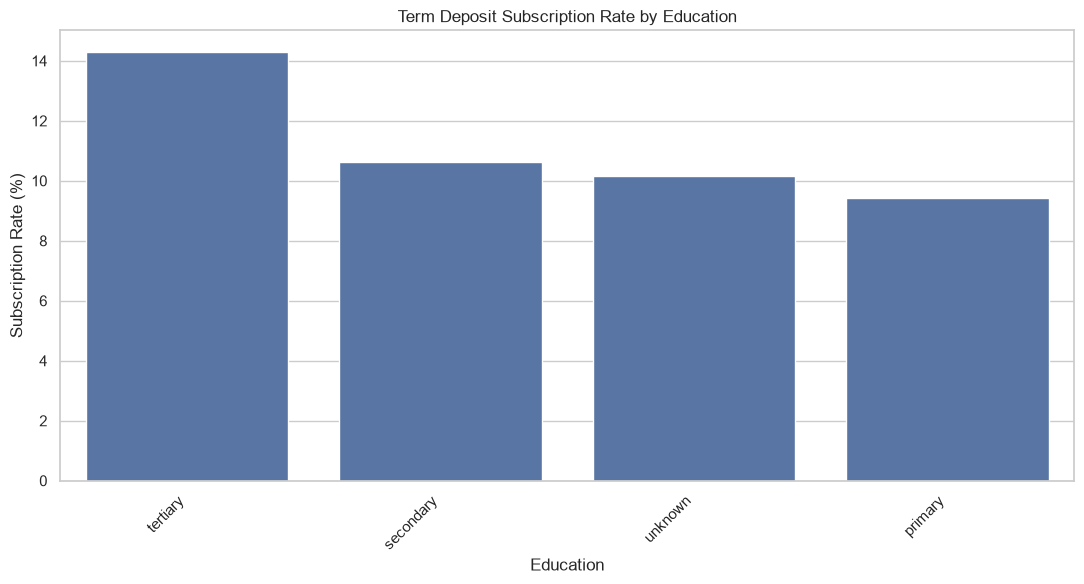

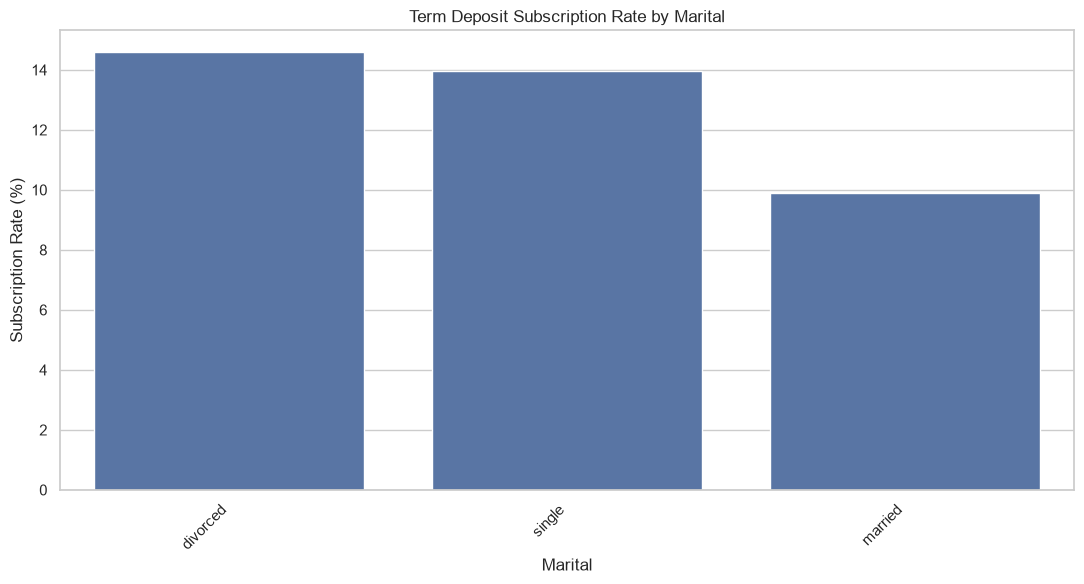

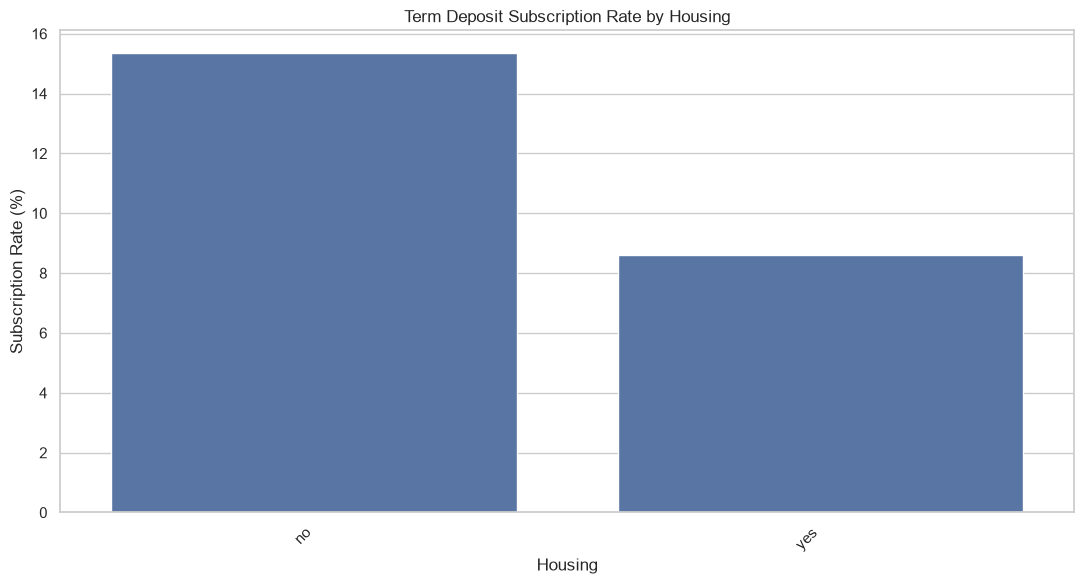

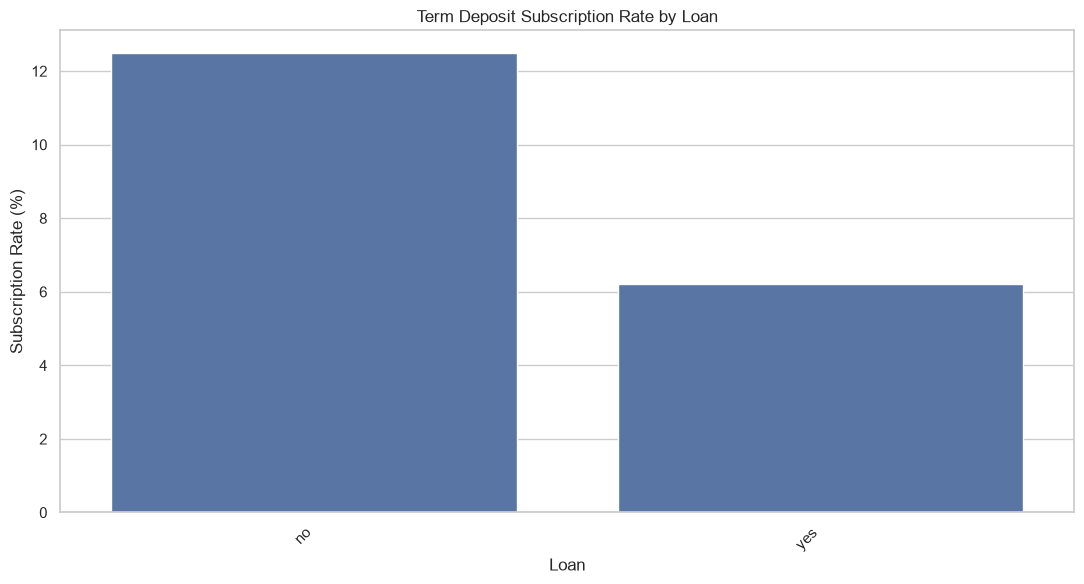

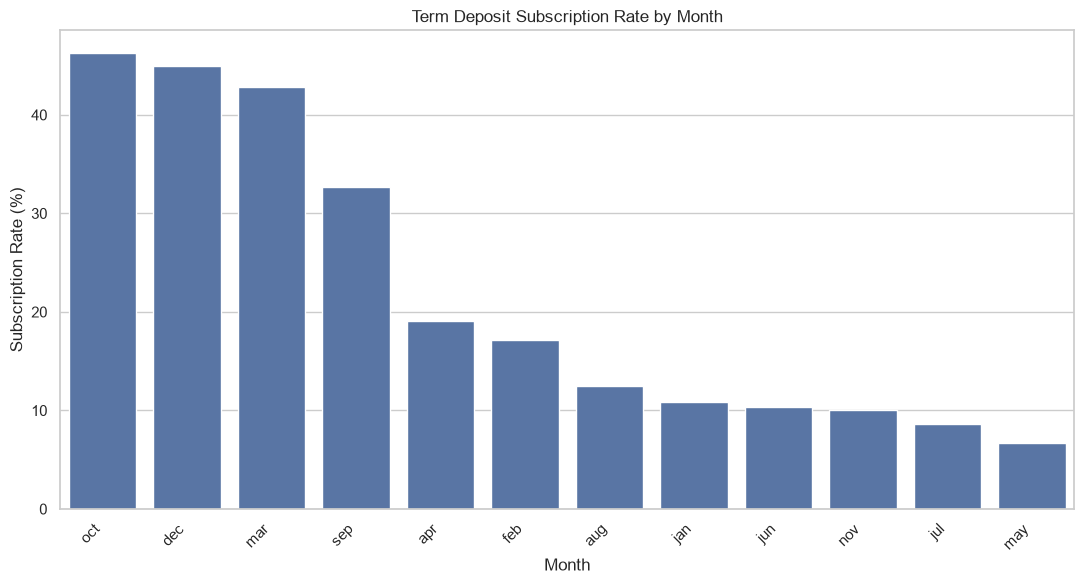

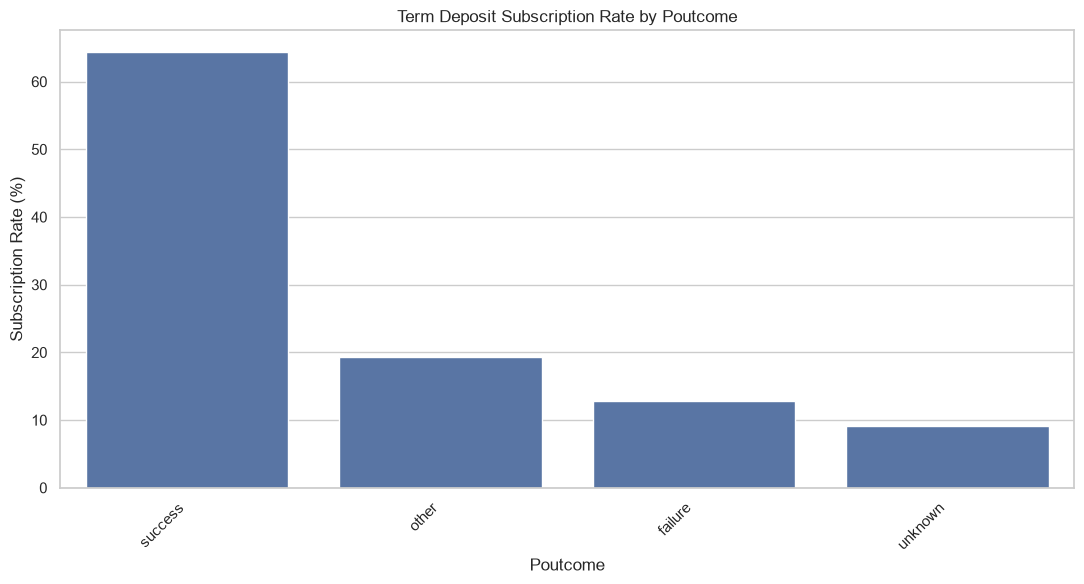

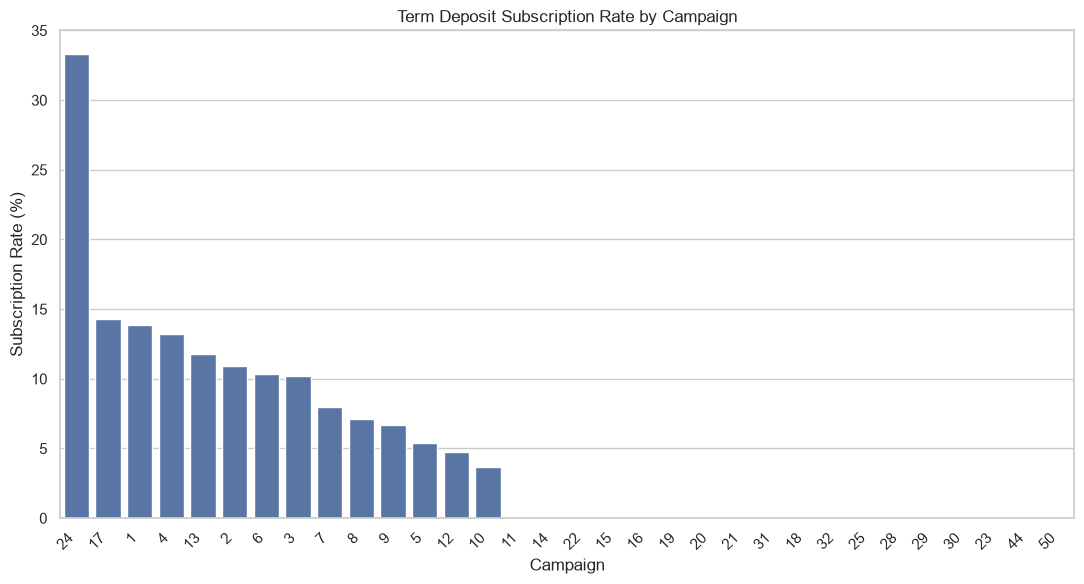


All categorical subscription-rate charts generated.


In [19]:
# Plot subscription rates for all seven categorical features

for feature in categorical_features:

    summary = categorical_summaries[feature].sort_values(
        "Subscription_Rate",
        ascending=False
    )

    plt.figure(figsize=(11, 6))

    sns.barplot(
        x=summary.index.astype(str),
        y=summary["Subscription_Rate"]
    )

    plt.title(f"Term Deposit Subscription Rate by {feature.title()}")
    plt.xlabel(feature.title())
    plt.ylabel("Subscription Rate (%)")
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()

    filename = f"07_subscription_rate_by_{feature}.png"

    plt.savefig(
        FIGURE_PATH / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("\nAll categorical subscription-rate charts generated.")

In [20]:
# Verify all categorical subscription-rate charts

categorical_figures = [
    FIGURE_PATH / f"07_subscription_rate_by_{feature}.png"
    for feature in categorical_features
]

for figure in categorical_figures:
    print(
        f"{figure.name}: "
        f"Exists = {figure.exists()}, "
        f"Size = {round(figure.stat().st_size / 1024, 2) if figure.exists() else 0} KB"
    )

assert all(figure.exists() for figure in categorical_figures)

print("\nSUCCESS: All 7 categorical charts are saved.")

07_subscription_rate_by_education.png: Exists = True, Size = 90.48 KB
07_subscription_rate_by_marital.png: Exists = True, Size = 81.6 KB
07_subscription_rate_by_housing.png: Exists = True, Size = 74.16 KB
07_subscription_rate_by_loan.png: Exists = True, Size = 68.92 KB
07_subscription_rate_by_month.png: Exists = True, Size = 90.04 KB
07_subscription_rate_by_poutcome.png: Exists = True, Size = 90.86 KB
07_subscription_rate_by_campaign.png: Exists = True, Size = 106.86 KB

SUCCESS: All 7 categorical charts are saved.


## Numerical Feature Analysis vs Subscription

This section investigates the relationship between numerical customer features and term-deposit subscription.

The analysis covers:
- Average numerical feature values for subscribers and non-subscribers.
- Distribution comparisons between the two target classes.
- Subscription patterns across numerical feature ranges.
- Potential relationships that may help identify customer segments.

The numerical features will be interpreted carefully, particularly when distributions are skewed or contain outliers.

Duration will be treated separately because it is only known after the customer call ends and may cause target leakage in a pre-call prediction model.

In [21]:
# Compare numerical feature statistics by subscription outcome

numerical_features = [
    "age",
    "balance",
    "day",
    "campaign",
    "pdays",
    "previous"
]

numerical_summary = (
    df.groupby("y")[numerical_features]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(numerical_summary)

age                balance                    day               \
      mean median    std     mean median      std   mean median   std   
y                                                                       
no   41.00   39.0  10.19  1403.21  419.5  3075.35  15.95   16.0  8.25   
yes  42.49   40.0  13.12  1571.96  710.0  2444.40  15.66   15.0  8.24   

    campaign               pdays                previous               
        mean median   std   mean median     std     mean median   std  
y                                                                      
no      2.86    2.0  3.21  36.01   -1.0   96.30     0.47    0.0  1.63  
yes     2.27    2.0  2.09  68.64   -1.0  121.96     1.09    0.0  2.06

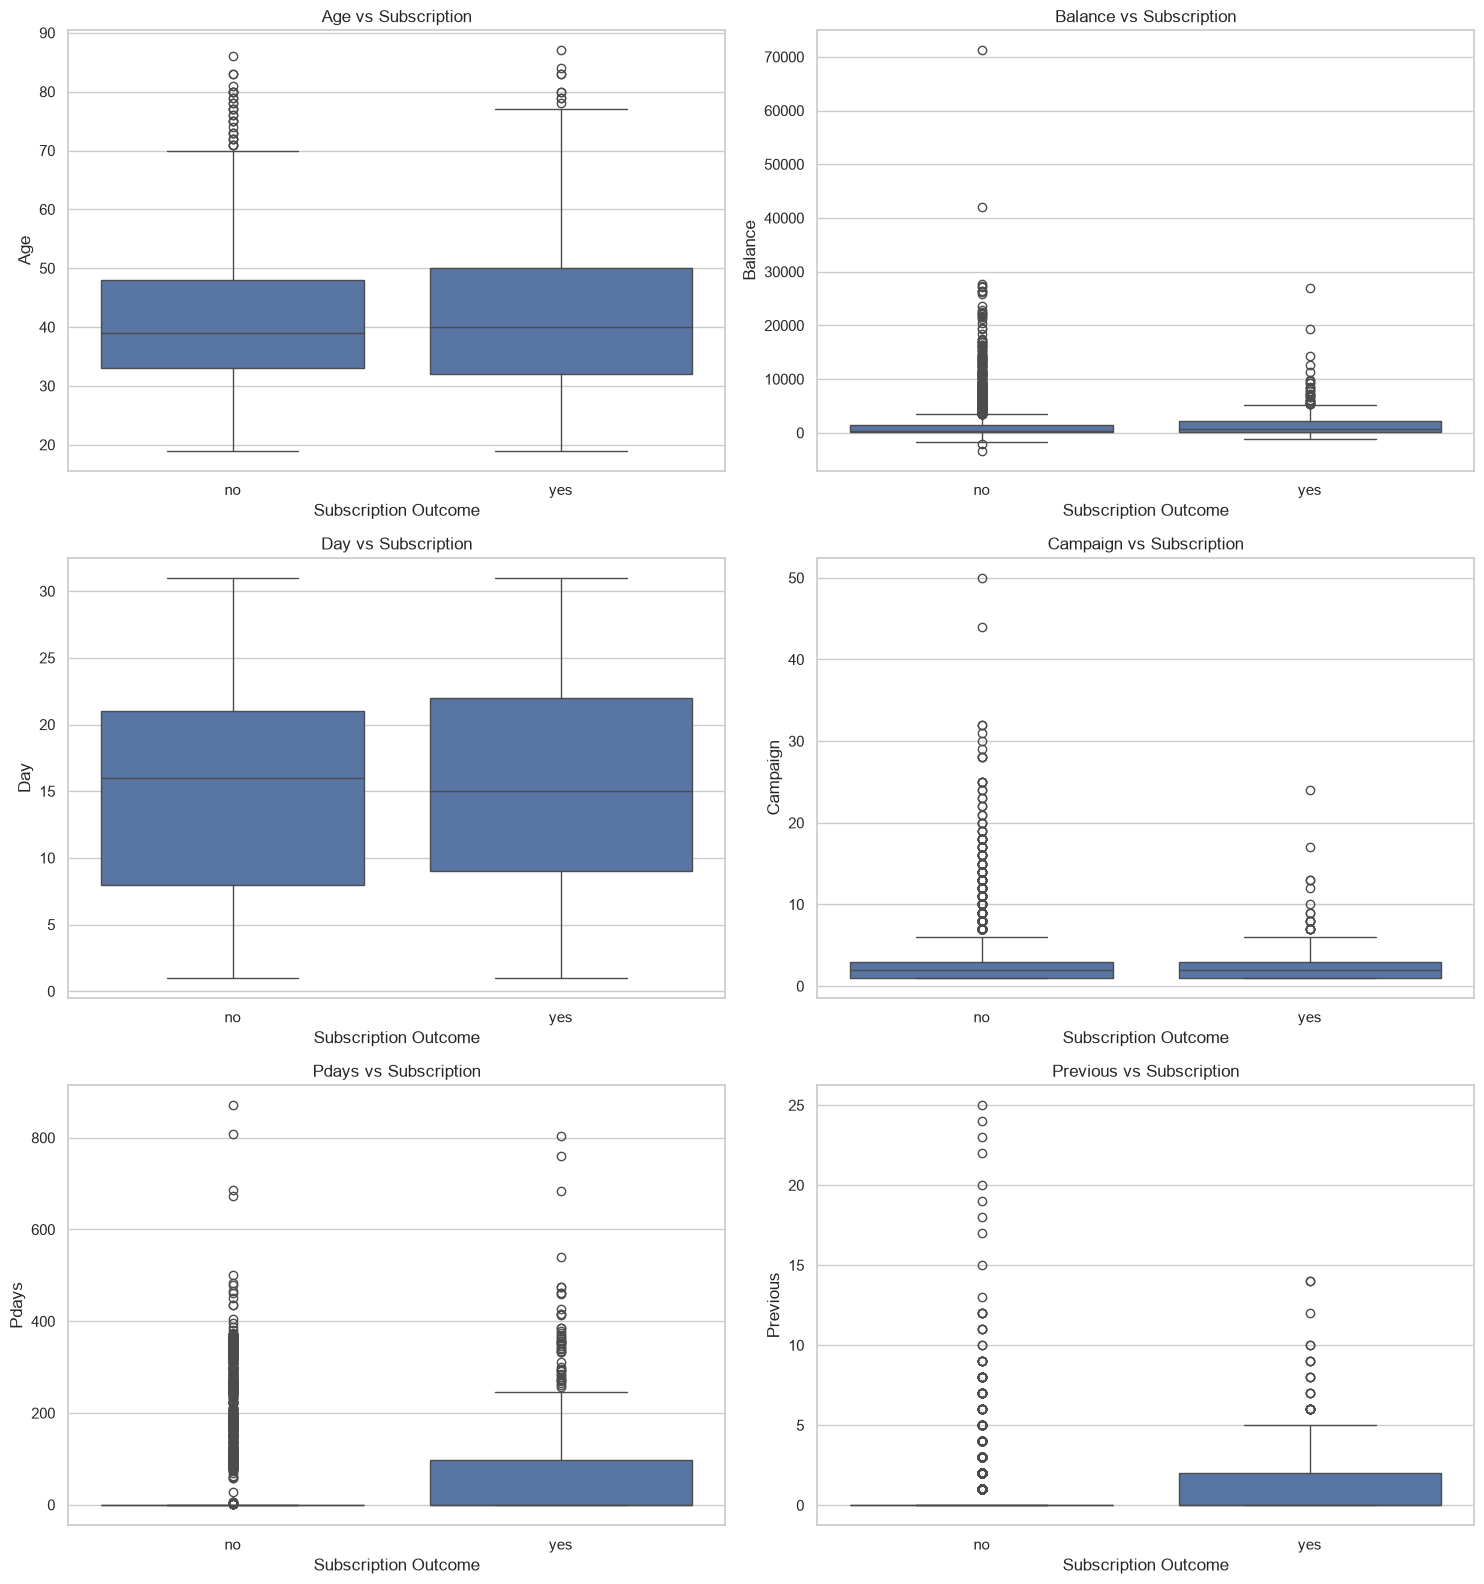

In [22]:
# Visual comparison of numerical features by subscription outcome

fig, axes = plt.subplots(3, 2, figsize=(15, 16))

for feature, ax in zip(numerical_features, axes.flatten()):
    sns.boxplot(
        data=df,
        x="y",
        y=feature,
        ax=ax
    )

    ax.set_title(f"{feature.capitalize()} vs Subscription")
    ax.set_xlabel("Subscription Outcome")
    ax.set_ylabel(feature.capitalize())

plt.tight_layout()

plt.savefig(
    FIGURE_PATH / "08_numerical_features_vs_subscription.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Observations – Numerical Features vs Subscription

### 1. Age
- Subscribers have a slightly higher median age than non-subscribers.
- Both groups show broadly similar age distributions.
- Age alone does not clearly separate subscribers from non-subscribers.

### 2. Balance
- Both groups contain highly right-skewed balance distributions.
- Several extreme balance values are visible.
- Subscribers have a higher average balance, as observed in the numerical summary.

### 3. Day
- The contact-day distributions are similar across both target groups.
- No major difference is visible from the boxplots.

### 4. Campaign
- Subscribers generally have fewer campaign contacts.
- Non-subscribers show more extreme campaign-contact values.
- Repeated contact attempts may be associated with lower subscription rates.

### 5. Pdays
- A large number of observations have a value of -1.
- This represents customers who were not previously contacted.
- The sentinel value must be interpreted separately from actual days since previous contact.

### 6. Previous
- Most customers have zero previous contacts.
- Subscribers show a somewhat wider distribution of previous contacts.
- Previous campaign history may provide useful predictive information.

### Overall Conclusion
Campaign history and customer balance appear to show differences between subscribers and non-subscribers. Age and contact day show relatively similar distributions.

These observations are exploratory and do not establish causation. Numerical features will be evaluated further during model development.

In [23]:
numerical_figure = (
    FIGURE_PATH / "08_numerical_features_vs_subscription.png"
)

print("Figure exists:", numerical_figure.exists())

if numerical_figure.exists():
    print(
        "Figure size:",
        round(numerical_figure.stat().st_size / 1024, 2),
        "KB"
    )

assert numerical_figure.exists()
assert numerical_figure.stat().st_size > 0

print("SUCCESS: Numerical comparison chart saved.")

Figure exists: True
Figure size: 402.73 KB
SUCCESS: Numerical comparison chart saved.


## Categorical Feature Analysis – Observations

### 1. Education
- Tertiary-educated customers have the highest subscription rate (14.30%).
- Secondary education follows at 10.62%.
- Primary education has the lowest rate (9.44%).

### 2. Marital Status
- Divorced customers have a subscription rate of 14.58%.
- Single customers have a rate of 13.96%.
- Married customers have a lower rate of 9.90%.

### 3. Housing Loan
- Customers without a housing loan have a subscription rate of 15.34%.
- Customers with a housing loan have a rate of 8.60%.

### 4. Personal Loan
- Customers without a personal loan have a subscription rate of 12.48%.
- Customers with a personal loan have a rate of 6.22%.

### 5. Contact Month
- October, December and March show the highest observed subscription rates.
- May has the lowest observed rate at 6.65%.
- Some months have relatively small sample sizes, so their rates require cautious interpretation.

### 6. Previous Campaign Outcome
- Customers with a successful previous campaign outcome have a subscription rate of 64.34%.
- Customers with an unknown previous outcome have a rate of 9.10%.
- Previous campaign success appears to be a particularly informative feature.

### 7. Campaign Contacts
- Campaign contact counts show varying subscription rates.
- The highest observed rate is for campaign count 24, but it represents only 3 customers.
- Higher campaign counts generally have small sample sizes and should not be interpreted as reliable trends.

### Overall Conclusion
Education, marital status, loan status, contact month and previous campaign outcome show differences in observed subscription rates.

Previous campaign outcome appears particularly informative. However, these are descriptive associations, and model evaluation will be needed to establish predictive usefulness.

# Final Exploratory Data Analysis Summary

## 1. Dataset Overview
- Total customer records: 4,521
- Total features: 16 predictors and 1 target variable.
- Target variable: y (yes/no).
- Subscribers: 521 (11.52%).
- Non-subscribers: 4,000 (88.48%).

## 2. Data Quality
- No missing values were identified.
- No duplicate records were identified.
- Unknown values were retained as explicit categories.
- Negative balances were retained because they can represent legitimate overdrafts.
- The value -1 in pdays represents customers who were not previously contacted.

## 3. Numerical Feature Findings
- Subscribers have a slightly higher average age and balance.
- Subscribers have fewer campaign contacts on average.
- Previous campaign contact history differs between the two target groups.
- Balance, campaign and other numerical features contain statistical outliers.
- Outliers were not automatically removed because they may represent legitimate customer behavior.

## 4. Categorical Feature Findings
- Tertiary-educated customers have a higher observed subscription rate than other education groups.
- Divorced and single customers show higher observed subscription rates than married customers.
- Customers without housing or personal loans show higher observed subscription rates.
- Subscription rates vary considerably across contact months.
- Previous campaign success has a strong observed association with subscription.

## 5. Correlation Analysis
- Most numerical feature pairs have weak linear correlations.
- The strongest observed relationship is between pdays and previous (approximately 0.58).
- Correlation does not establish causation.

## 6. Data Leakage Consideration
- Duration represents the length of the last contact.
- It is only known after the call ends.
- Therefore, duration is excluded from pre-call prediction model inputs.

## 7. Class Imbalance
- The target distribution is imbalanced.
- Only 11.52% of customers subscribed.
- Model evaluation should consider precision, recall, F1-score and PR-AUC rather than accuracy alone.

## 8. Conclusion
Exploratory analysis identified several potentially informative customer and campaign characteristics.

Previous campaign outcome, loan status, contact month and campaign history show differences in observed subscription rates.

These findings will guide feature engineering and model development. Predictive usefulness will be assessed using appropriate validation techniques.